In [30]:
import pandas as pd
import matplotlib.pyplot as plt


In [31]:
mca_df = pd.read_csv('../data/auxiliary/final_mca_soc_code.csv')
mca_df["Job Sector"] = (
    mca_df["Job Sector"].replace(
        {
            "Arts, entertainment and recreation": "Arts, Entertainment and Recreation",
            "Professional, Scientific And Technical Activities" : "Professional, Scientific and Technical Activities"
        }
    )
)

ai_measurements_df = pd.read_csv('../data/auxiliary/stage_3_archetypes.csv')

In [33]:
final_mca_df = (
    mca_df
    .merge(
        ai_measurements_df, 
        how='left', 
        left_on='SOC Code', 
        right_on='O*NET-SOC Code'
    )
)

In [34]:
final_mca_df.to_csv('../data/auxiliary/final_mca_with_ai_measurements.csv', index=False)

In [35]:
ai_numeric_cols = [
    "AIOE",
    "Complementarity",
    "C-AIOE",
    "Observed Exposure",
    "LLM Rating Beta",
    "Human Rating Beta",
    "Augmentation Percent",
    "Automation Percent",
    "Directive Percent",
    "Feedback Loop Percent",
    "Learning Percent",
    "Task Iteration Percent",
    "Validation Percent",
    "None Percent",
]

df = final_mca_df.copy()

for col in ai_numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

archetype_order = [
    "Limited Current Transformation",
    "Latent Transformation",
    "AI-Enabled Expansion",
    "Active Transformation",
]

archetype_col = "Archetype C-AIOE Percentile - Observed Exposure 50"

activity_cols = [
    "Directive Percent",
    "Feedback Loop Percent",
    "Learning Percent",
    "Task Iteration Percent",
    "Validation Percent",
    "None Percent",
]

df[archetype_col] = df[archetype_col].astype("category")

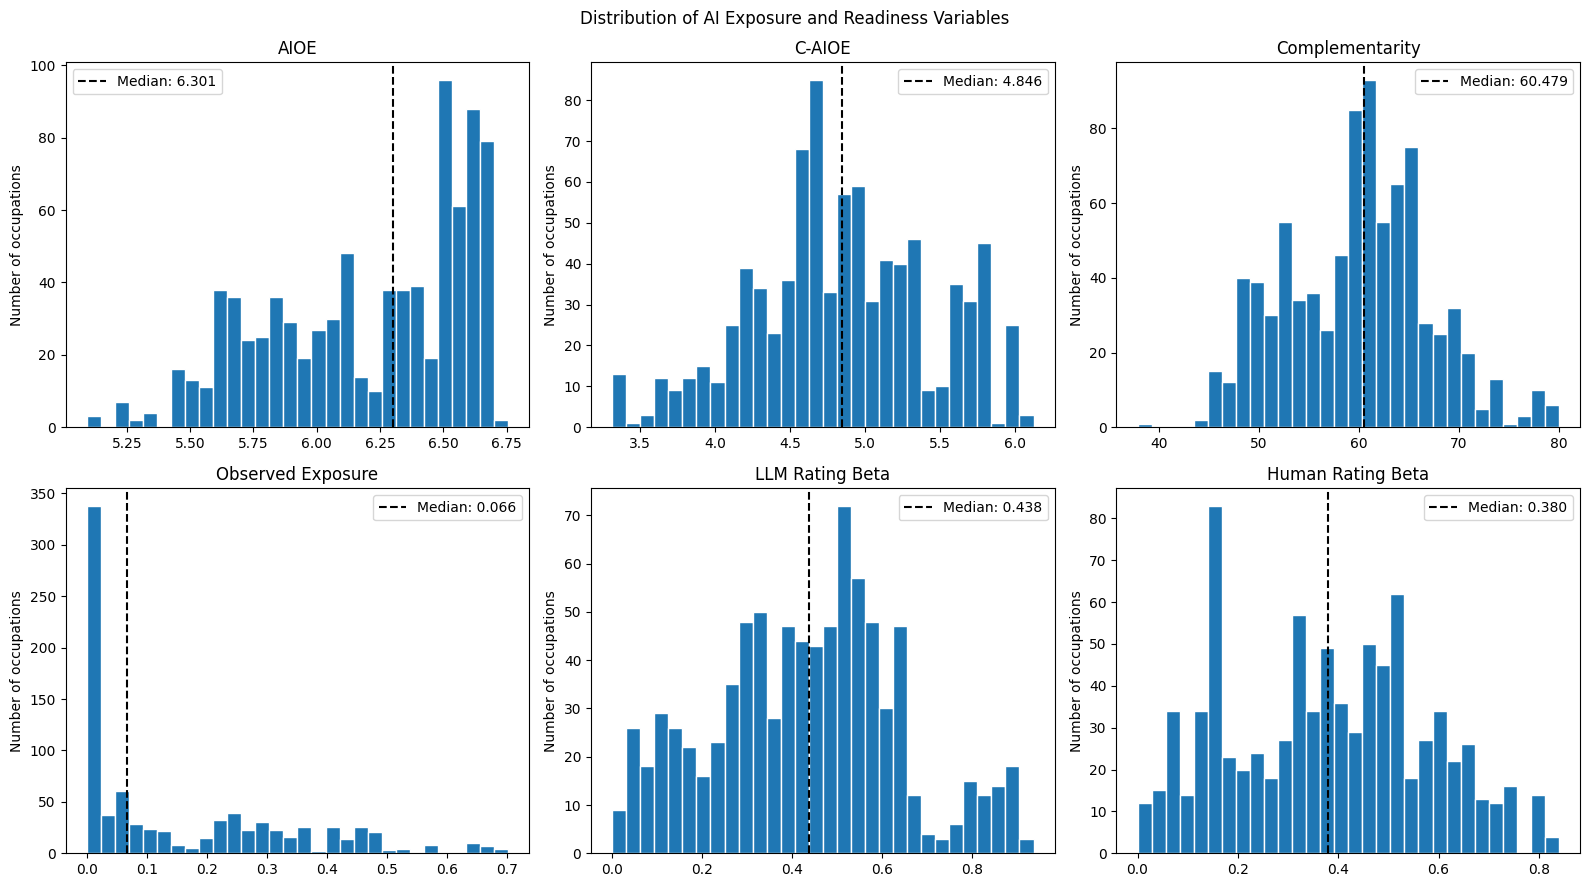

In [36]:
distribution_cols = [
    "AIOE",
    "C-AIOE",
    "Complementarity",
    "Observed Exposure",
    "LLM Rating Beta",
    "Human Rating Beta",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, distribution_cols):
    values = df[col].dropna()

    ax.hist(values, bins=30, edgecolor="white")
    ax.axvline(
        values.median(),
        color="black",
        linestyle="--",
        label=f"Median: {values.median():.3f}",
    )
    ax.set_title(col)
    ax.set_ylabel("Number of occupations")
    ax.legend()

fig.suptitle("Distribution of AI Exposure and Readiness Variables")
fig.tight_layout()
plt.show()

observed = df["Observed Exposure"].dropna()

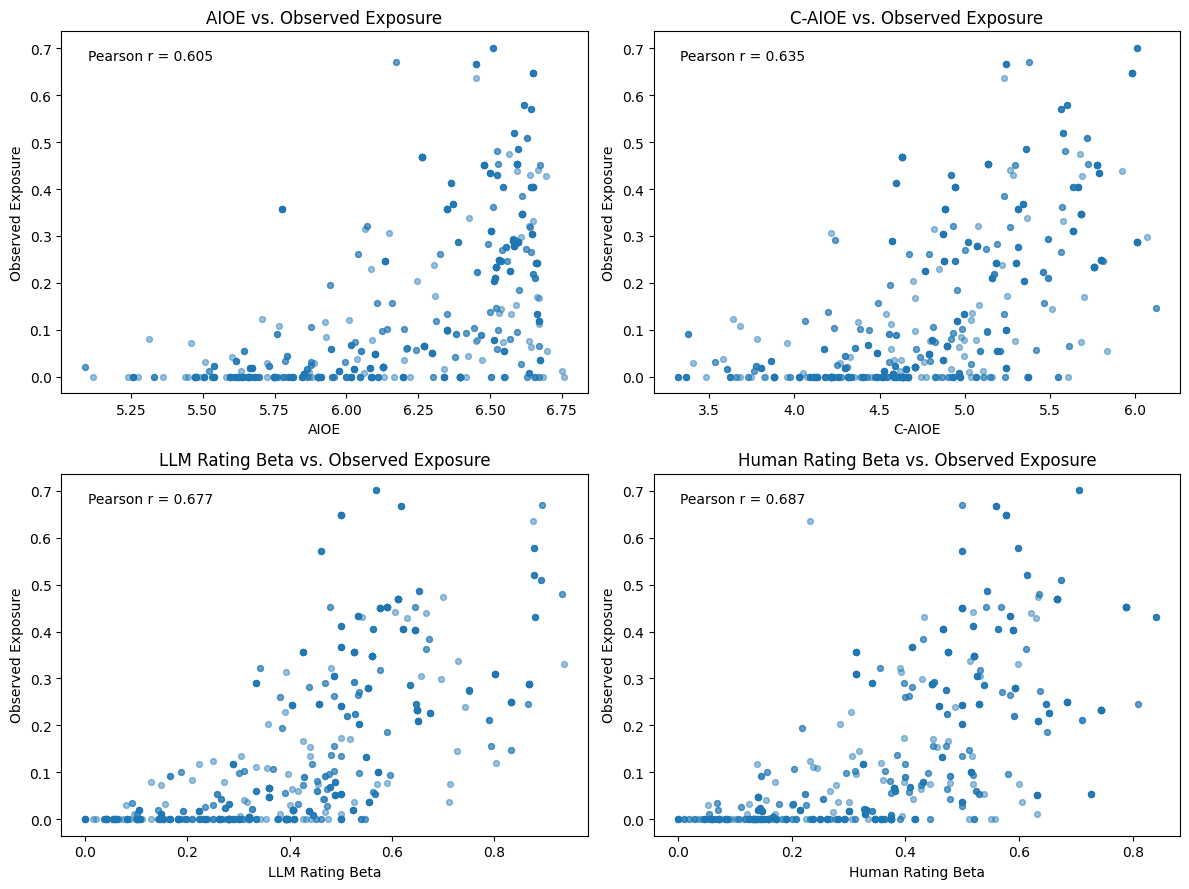

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

scatter_specs = [
    ("AIOE", "Observed Exposure", "AIOE vs. Observed Exposure"),
    ("C-AIOE", "Observed Exposure", "C-AIOE vs. Observed Exposure"),
    ("LLM Rating Beta", "Observed Exposure", "LLM Rating Beta vs. Observed Exposure"),
    ("Human Rating Beta", "Observed Exposure", "Human Rating Beta vs. Observed Exposure"),
]

for ax, (x_col, y_col, title) in zip(axes.flat, scatter_specs):
    plot_df = df[[x_col, y_col]].dropna()

    ax.scatter(
        plot_df[x_col],
        plot_df[y_col],
        alpha=0.45,
        s=18,
    )

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(title)

    corr = plot_df[x_col].corr(plot_df[y_col])

    ax.text(
        0.05,
        0.95,
        f"Pearson r = {corr:.3f}",
        transform=ax.transAxes,
        va="top",
    )

fig.tight_layout()
plt.show()

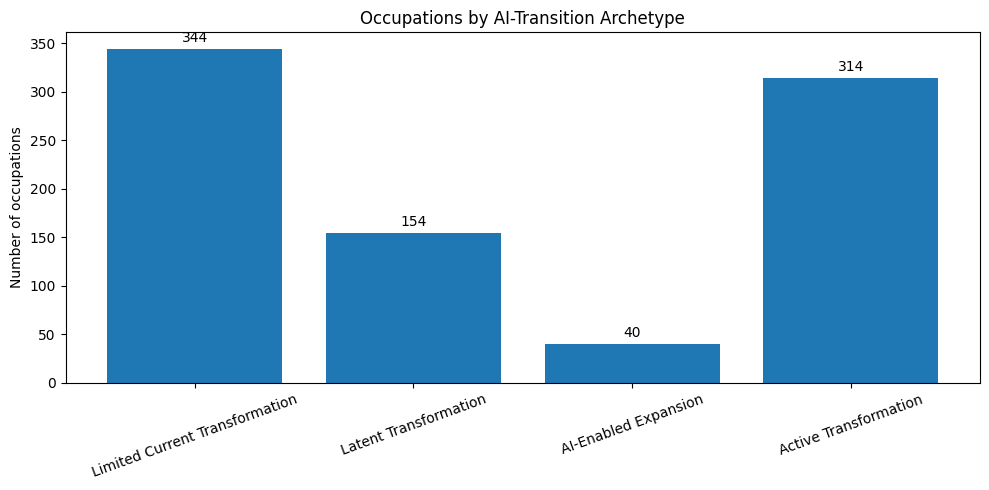

                                                    Count  Share (%)
Archetype C-AIOE Percentile - Observed Exposure 50                  
Limited Current Transformation                        344      40.38
Latent Transformation                                 154      18.08
AI-Enabled Expansion                                   40       4.69
Active Transformation                                 314      36.85


In [38]:
counts = df[archetype_col].value_counts().reindex(archetype_order).dropna()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    counts.index.astype(str),
    counts.values,
)

ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_ylabel("Number of occupations")
ax.set_title("Occupations by AI-Transition Archetype")
ax.tick_params(axis="x", rotation=20)

fig.tight_layout()
plt.show()

print(
    pd.DataFrame({
        "Count": counts,
        "Share (%)": counts / counts.sum() * 100,
    }).round(2)
)

In [39]:
df[df['Archetype C-AIOE'] == 'AI-Enabled Expansion'][['Job Title']]

KeyError: 'Archetype C-AIOE'

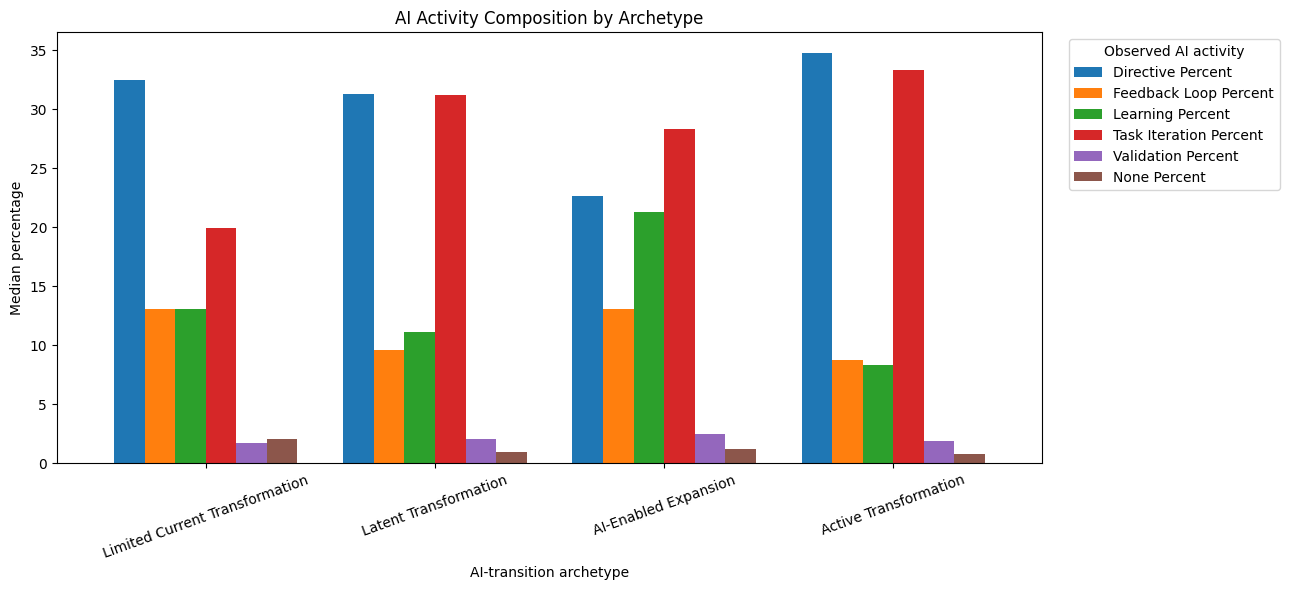

In [40]:
activity_medians = (
    df.groupby(archetype_col, observed=True)[activity_cols]
    .median()
    .reindex(archetype_order)
)

fig, ax = plt.subplots(figsize=(13, 6))

activity_medians.plot(
    kind="bar",
    ax=ax,
    width=0.8,
)

ax.set_xlabel("AI-transition archetype")
ax.set_ylabel("Median percentage")
ax.set_title("AI Activity Composition by Archetype")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Observed AI activity", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.tight_layout()
plt.show()

In [41]:
pd.crosstab(df['Job Sector'], df['Archetype C-AIOE Percentile - Observed Exposure 50'], margins=True).sort_values(by='Active Transformation')

Archetype C-AIOE Percentile - Observed Exposure 50,AI-Enabled Expansion,Active Transformation,Latent Transformation,Limited Current Transformation,All
Job Sector,,,,,
"Water Supply; Sewerage, Waste Management and Remediation",0,0,4,0,4
"Electricity, Gas, Steam and Air Conditioning Supply",0,0,4,16,20
Other Service Activities,0,1,4,9,14
Real Estate Activities,0,3,0,0,3
"Agriculture, Forestry, and Fishing",2,3,5,50,60
Wholesale and Retail Trade; Repair of Motor Vehicles and Motorcycles,3,5,2,0,10
Accommodation and Food Service Activities,0,12,9,28,49
Construction,0,12,8,36,56
Education,11,13,9,15,48


In [42]:
df.query(
    "`Archetype C-AIOE Percentile - Observed Exposure 50` == 'AI-Enabled Expansion' and "
    "`Job Sector` == 'Wholesale and Retail Trade; Repair of Motor Vehicles and Motorcycles'"
)

,Job Title,Educational Qualification,Job Sector,Educational Pathway,HEI with PRC Exam,Some HEI,Job Subsector,PSOC Code,ISCO Code,SOC Code,...,Archetype C-AIOE Percentile - Observed Exposure 80,Augmentation Percent,Automation Percent,Directive Percent,Feedback Loop Percent,Learning Percent,Task Iteration Percent,Validation Percent,None Percent,Sub-Archetype
135,Store Supervisor Trainee,Bachelor of Business Distributive Arts,Wholesale and Retail Trade; Repair of Motor Ve...,Higher Education,No,No,Retail sale in non-specialized and specialized...,5222,5222,41-1011.00,...,Limited Current Transformation,56.41,43.59,25.91,13.07,10.73,37.23,2.48,10.58,AI-Powered
664,Online Store Executive Assistant,No Match Found,Wholesale and Retail Trade; Repair of Motor Ve...,Higher Education,No,Yes,Retail Sale via Mail Order Houses or via Internet,5222,5222,41-1011.00,...,Limited Current Transformation,56.41,43.59,25.91,13.07,10.73,37.23,2.48,10.58,AI-Powered
1050,Store Keeper,No Match Found,Wholesale and Retail Trade; Repair of Motor Ve...,Not Higher Education,No,No,Retail sale in non-specialized stores,5221,5221,11-1021.00,...,Limited Current Transformation,56.68,43.32,28.56,13.94,3.84,50.78,0.97,1.90,AI-Powered
